In [1]:
import pandas as pd, numpy as np, re, io, warnings
from scipy import stats
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PowerTransformer
from itertools import combinations
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)

# >>> Change this path if your file is somewhere else <<<
import os
CANDIDATES = ['nc_merged_customers.csv',
              '1792312434490_nc_merged_customers.csv',
              '/mnt/user-data/uploads/1792312434490_nc_merged_customers.csv']
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
NOW = pd.Timestamp('2026-10-18')        # reference date for tenure / recency
df = pd.read_csv(DATA_PATH, low_memory=False)
print(DATA_PATH, df.shape)
df.head()

nc_merged_customers.csv (185000, 16)


,record_id,source_system,full_name,email,phone,address,city,state,zip_code,created_date,customer_status,invoice_count,total_billed,last_invoice_date,payment_method,true_customer_id
0,CRM0000001,CRM,Nathan Nance,nnance17@example.com,NaN,1142 Noah Road,Graham,NC,27253,2012-01-11,Active,NaN,NaN,NaN,NaN,CUST073258
1,CRM0000002,CRM,Jonathan L. Henson,jonathan.henson3@mail.example,NaN,4881 Grosbeak Ct,Mebane,NC,27302,2025-07-18,Active,NaN,NaN,NaN,NaN,CUST008947
2,CRM0000003,CRM,Dylan H. Wilkerson,dylan_wilkerson70@example.org,(336) 212-8627,5609 Herring Hillside Dr,Graham,NC,27253,2017-12-28,Inactive,NaN,NaN,NaN,NaN,CUST052862
3,CRM0000004,CRM,Frankie King,frankie_king39@post.example,NaN,1452 Gant Rd,Graham,NC,27253,2016-09-19,Active,NaN,NaN,NaN,NaN,CUST047988
4,CRM0000005,CRM,Felecia Cromity,felecia.cromity6@example.org,NaN,1315 Lansdowne Dr,Mebane,NC,27302,2024-09-09,Active,NaN,NaN,NaN,NaN,CUST057466


## 1. Information
`info()` shows column types and non-null counts. Note: `zip_code` is numeric but is really a category, so convert it to string.

In [2]:
df.info()
print('Memory (MB):', round(df.memory_usage(deep=True).sum()/1e6, 1))
print()
print('Rows per source:'); print(df.source_system.value_counts())
print('Unique true customers:', df.true_customer_id.nunique())
df.describe(include='all').T

<class 'pandas.DataFrame'>
RangeIndex: 185000 entries, 0 to 184999
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   record_id          185000 non-null  str    
 1   source_system      185000 non-null  str    
 2   full_name          185000 non-null  str    
 3   email              181012 non-null  str    
 4   phone              138705 non-null  str    
 5   address            177143 non-null  str    
 6   city               185000 non-null  str    
 7   state              185000 non-null  str    
 8   zip_code           185000 non-null  int64  
 9   created_date       99963 non-null   str    
 10  customer_status    100000 non-null  str    
 11  invoice_count      85000 non-null   float64
 12  total_billed       85000 non-null   float64
 13  last_invoice_date  85000 non-null   str    
 14  payment_method     85000 non-null   str    
 15  true_customer_id   185000 non-null  str    
dtypes: float64(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,185000,185000,CRM0000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_system,185000,2,CRM,100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
full_name,185000,153962,James Smith,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
email,181012,121513,bboffo93@inbox.example,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
phone,138705,102366,(336) 000-0000,389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
address,177143,83919,700 E Haggard Ave,193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,185000,13,Burlington,81415,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,185000,1,NC,185000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zip_code,185000.0,NaN,NaN,NaN,27247.493297,36.693324,27215.0,27215.0,27244.0,27258.0,27516.0
created_date,99963,11579,2026-01-02,656,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Duplicates
Exact duplicates are easy to drop. The rest differ by typos and formats, so they need fuzzy matching.

In [3]:
cols = [c for c in df.columns if c != 'record_id']
print('Exact duplicate rows (ignoring record_id):', df.duplicated(subset=cols).sum())
print('Duplicate on full_name + email          :', df.dropna(subset=['email']).duplicated(subset=['full_name','email']).sum())
print('Duplicate on email (exact)              :', df.dropna(subset=['email']).duplicated(subset=['email']).sum())
print('Duplicate on full_name + zip + address  :', df.dropna(subset=['address']).duplicated(subset=['full_name','zip_code','address']).sum())
print('Rows beyond first per true_customer_id  :', df.duplicated('true_customer_id').sum())

sz = df.groupby('true_customer_id').size()
print('\nRecords per true customer:'); print(sz.value_counts().sort_index())
per_src = df.groupby(['true_customer_id','source_system']).size()
print('\nCustomers with >1 record in the SAME system:'); print(per_src[per_src>1].groupby(level=1).size())
print('Customers present in both systems:', (df.groupby('true_customer_id').source_system.nunique()==2).sum())
pairs = (sz*(sz-1)//2).sum(); total = len(df)*(len(df)-1)//2
print(f'\nTrue duplicate pairs: {pairs:,} of {total:,} possible ({pairs/total:.6%})')

# example cluster
ex = sz[sz==4].index[0]
df[df.true_customer_id==ex]

Exact duplicate rows (ignoring record_id): 314
Duplicate on full_name + email          : 19426
Duplicate on email (exact)              : 59499
Duplicate on full_name + zip + address  : 19325
Rows beyond first per true_customer_id  : 95000

Records per true customer:
1    16577
2    53385
3    18499
4     1539
Name: count, dtype: int64

Customers with >1 record in the SAME system:
source_system
BILLING     9000
CRM        16000
dtype: int64
Customers present in both systems: 70000

True duplicate pairs: 118,116 of 17,112,407,500 possible (0.000690%)


,record_id,source_system,full_name,email,phone,address,city,state,zip_code,created_date,customer_status,invoice_count,total_billed,last_invoice_date,payment_method,true_customer_id
20544,CRM0020545,CRM,Roxsee Stover,rstover81@post.example,(910) 232-7119,1555 Moore'S Chapel Cemetary Rd,Graham,NC,27253,2015-08-19,Active,NaN,NaN,NaN,NaN,CUST000008
52574,CRM0052575,CRM,Roxsee Stover,rsstover81@post.example,9102327119,1555 Moore'S Chapel Cemetary Road,Graham,NC,27253,2015-08-19,Active,NaN,NaN,NaN,NaN,CUST000008
118301,BIL0018302,BILLING,R. Stover,rstover81@post.example,9102327119,1555 Moore'S Chapel Cemetary Road,Graham,NC,27253,NaN,NaN,47.0,13001.96,2026-04-25,Invoice,CUST000008
136059,BIL0036060,BILLING,"Stover, Roxsee",rstover81@post.example,+1 910 232 7119,1555 Moore'S Chapel Cemetary Rd,Graham,NC,27253,NaN,NaN,7.0,9522.85,2026-09-16,Direct Debit,CUST000008


## 3. Missing values
Columns that exist only in one system (created_date, status, invoice fields) are *structurally* empty. The real gaps are phone, address and email.
We test whether missingness is random using a chi-square test against source and city.

,missing,percent
record_id,0,0.00
source_system,0,0.00
full_name,0,0.00
email,3988,2.16
phone,46295,25.02
address,7857,4.25
city,0,0.00
state,0,0.00
zip_code,0,0.00
created_date,85037,45.97


Rows missing both email and phone      : 1205
Rows missing email, phone and address  : 127

Missing % by source:


,email,phone,address
source_system,,,
BILLING,3.69,27.25,7.30
CRM,0.85,23.13,1.65


phone    missing vs source p=4.25e-92 | vs city p=4.21e-101
address  missing vs source p=0.00e+00 | vs city p=6.42e-01
email    missing vs source p=0.00e+00 | vs city p=3.27e-01


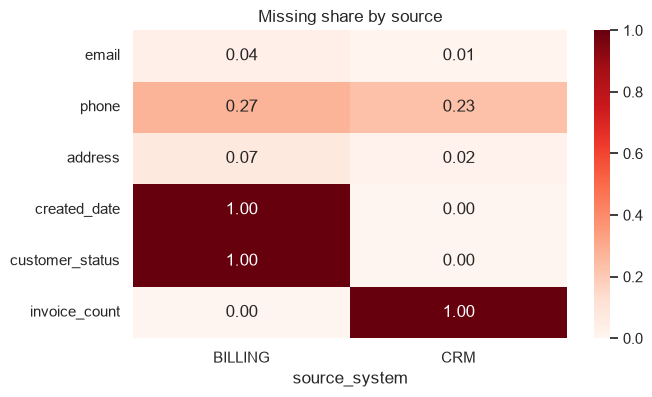

In [4]:
mi = df.isna().sum()
miss = pd.DataFrame({'missing': mi, 'percent': (mi/len(df)*100).round(2)})
display(miss)
print('Rows missing both email and phone      :', (df.email.isna() & df.phone.isna()).sum())
print('Rows missing email, phone and address  :', (df.email.isna() & df.phone.isna() & df.address.isna()).sum())

print('\nMissing % by source:')
display((df.groupby('source_system')[['email','phone','address']].apply(lambda x: x.isna().mean()*100)).round(2))

for col in ['phone','address','email']:
    flag = df[col].isna()
    p_src = stats.chi2_contingency(pd.crosstab(df.source_system, flag))[1]
    p_city = stats.chi2_contingency(pd.crosstab(df.city, flag))[1]
    print(f'{col:8s} missing vs source p={p_src:.2e} | vs city p={p_city:.2e}')

plt.figure(figsize=(7,4))
sns.heatmap(df[['email','phone','address','created_date','customer_status','invoice_count']].isna().groupby(df.source_system).mean().T,
            annot=True, fmt='.2f', cmap='Reds'); plt.title('Missing share by source'); plt.show()

**Reading:** p < 0.05 means missingness depends on source/city (not random, i.e. MAR). So do **not** fill contact fields with mean/mode. Keep nulls, add `has_email / has_phone / has_address` flags, and fill from the other records of the same customer after matching.

## 4. Feature engineering (numeric features)
The file has only 3 numeric columns, so we derive more. Billing and CRM are analysed separately.

| Feature | Meaning |
|---|---|
| avg_invoice | total_billed / invoice_count |
| days_since_last | days from last invoice to reference date |
| tenure_years | years since CRM created_date |
| name_len | characters in name |
| n_missing_contact | how many of email/phone/address are empty |
| cluster_size | records of the same true customer |

In [5]:
bil = df[df.source_system=='BILLING'].copy()
bil['avg_invoice']       = bil.total_billed / bil.invoice_count
bil['days_since_last']   = (NOW - pd.to_datetime(bil.last_invoice_date)).dt.days
bil['name_len']          = bil.full_name.str.len()
bil['n_missing_contact'] = bil[['email','phone','address']].isna().sum(axis=1)
bil['cluster_size']      = bil.true_customer_id.map(df.true_customer_id.value_counts())

crm = df[df.source_system=='CRM'].copy()
crm['tenure_years']      = (NOW - pd.to_datetime(crm.created_date)).dt.days/365.25
crm['name_len']          = crm.full_name.str.len()
crm['n_missing_contact'] = crm[['email','phone','address']].isna().sum(axis=1)
crm['cluster_size']      = crm.true_customer_id.map(df.true_customer_id.value_counts())

NUMB = ['invoice_count','total_billed','avg_invoice','days_since_last','name_len','n_missing_contact','cluster_size']
NUMC = ['tenure_years','name_len','n_missing_contact','cluster_size']
print(bil.shape, crm.shape)

(85000, 21) (100000, 20)


## 5. Variance, skewness and kurtosis
- **Variance / std:** spread. It depends on the scale, so compare with **CV% = std/mean x 100** (scale-free).
- **Skewness:** 0 symmetric, + right tail. |skew| > 1 is high.
- **Excess kurtosis:** 0 = normal-like tails, + heavy tails/extreme values, - flat.

In [6]:
def shape_table(d, cols):
    return pd.DataFrame({'n': d[cols].count(), 'mean': d[cols].mean(), 'median': d[cols].median(),
        'std': d[cols].std(), 'variance': d[cols].var(), 'CV%': d[cols].std()/d[cols].mean()*100,
        'skew': d[cols].skew(), 'excess_kurt': d[cols].kurt(), 'min': d[cols].min(), 'max': d[cols].max()}).round(3)
print('BILLING'); display(shape_table(bil, NUMB))
print('CRM');     display(shape_table(crm, NUMC))

BILLING


,n,mean,median,std,variance,CV%,skew,excess_kurt,min,max
invoice_count,85000,30.512,31.000,17.344,3.008100e+02,56.843,-0.001,-1.209,1.00,60.00
total_billed,85000,12582.474,12570.655,7183.610,5.160426e+07,57.092,-0.006,-1.196,50.27,24998.40
avg_invoice,85000,975.800,411.757,2154.675,4.642625e+06,220.811,6.283,49.277,0.89,24990.32
days_since_last,85000,216.766,217.000,115.828,1.341603e+04,53.434,-0.002,-1.201,17.00,417.00
name_len,85000,13.049,13.000,3.165,1.001800e+01,24.254,0.714,1.574,5.00,34.00
n_missing_contact,85000,0.382,0.000,0.553,3.060000e-01,144.675,1.134,0.519,0.00,3.00
cluster_size,85000,2.307,2.000,0.640,4.090000e-01,27.731,0.451,0.296,1.00,4.00


CRM


,n,mean,median,std,variance,CV%,skew,excess_kurt,min,max
tenure_years,99963,14.052,7.984,14.290,204.211,101.698,1.377,1.182,0.027,79.997
name_len,100000,14.512,14.000,3.018,9.108,20.796,0.876,1.575,5.000,34.000
n_missing_contact,100000,0.256,0.000,0.456,0.208,177.801,1.403,0.803,0.000,3.000
cluster_size,100000,2.251,2.000,0.690,0.476,30.638,0.188,-0.073,1.000,4.000


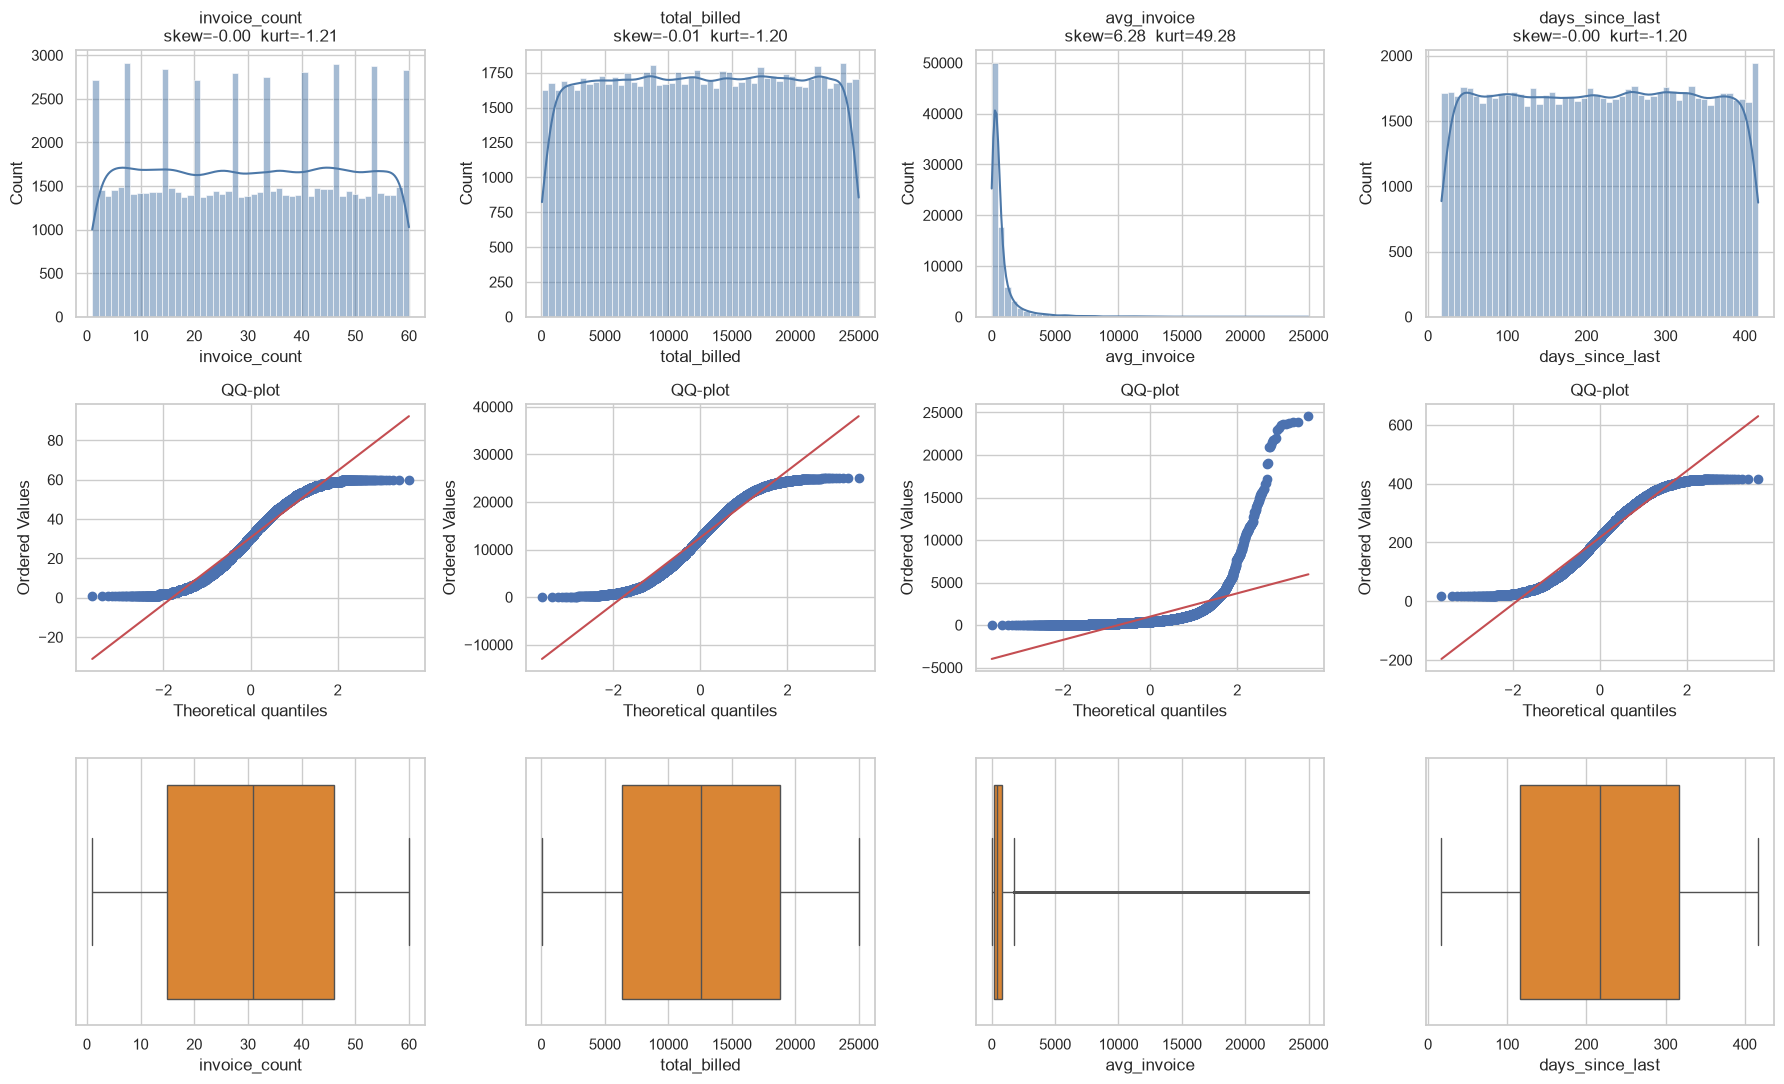

In [7]:
fig, ax = plt.subplots(3, 4, figsize=(18, 11))
for j, c in enumerate(['invoice_count','total_billed','avg_invoice','days_since_last']):
    x = bil[c].dropna()
    sns.histplot(x, bins=50, kde=True, ax=ax[0,j], color='#4C78A8'); ax[0,j].set_title(f'{c}\nskew={x.skew():.2f}  kurt={x.kurt():.2f}')
    stats.probplot(x.sample(5000, random_state=0), dist='norm', plot=ax[1,j]); ax[1,j].set_title('QQ-plot')
    sns.boxplot(x=x, ax=ax[2,j], color='#F58518', fliersize=1)
plt.tight_layout(); plt.show()

**Reading:** `invoice_count`, `total_billed`, `days_since_last` have skew ~0 and kurtosis ~ -1.2: a flat, uniform-like shape (do **not** log them). `avg_invoice` has skew ~6.3 and kurtosis ~49: very high, so it needs a transform (section 8).

## 6. Outliers
Two methods: **IQR** (outside Q1-1.5xIQR or Q3+1.5xIQR, good for skewed data) and **Z-score** (|z|>3, better for normal data).
Outliers are checked for validity first and only transformed or capped, not blindly deleted.

In [8]:
def outliers(d, cols):
    rows = []
    for c in cols:
        x = d[c].dropna(); q1, q3 = x.quantile([.25, .75]); i = q3 - q1
        lo, hi = q1 - 1.5*i, q3 + 1.5*i
        m = (x < lo) | (x > hi)
        rows.append((c, int(m.sum()), round(m.mean()*100, 2), int((abs(stats.zscore(x)) > 3).sum()), round(lo,2), round(hi,2)))
    return pd.DataFrame(rows, columns=['column','IQR_outliers','IQR_%','abs_z_gt_3','low_fence','high_fence'])
print('BILLING'); display(outliers(bil, NUMB))
print('CRM');     display(outliers(crm, NUMC))

x = bil.avg_invoice
xw = x.clip(x.quantile(.01), x.quantile(.99))
print(f'avg_invoice skew: raw {x.skew():.2f} | winsorized(1-99%) {xw.skew():.2f} | log1p {np.log1p(x).skew():.2f}')
print(f'avg_invoice kurt: raw {x.kurt():.2f} | winsorized {xw.kurt():.2f} | log1p {np.log1p(x).kurt():.2f}')
print('Oldest CRM created_date:', crm.created_date.min(), '(check plausibility)')

BILLING


,column,IQR_outliers,IQR_%,abs_z_gt_3,low_fence,high_fence
0,invoice_count,0,0.00,0,-31.50,92.50
1,total_billed,0,0.00,0,-12227.35,37414.64
2,avg_invoice,9652,11.36,1659,-701.63,1724.34
3,days_since_last,0,0.00,0,-185.50,618.50
4,name_len,1490,1.75,995,5.00,21.00
5,n_missing_contact,98,0.12,98,-1.50,2.50
6,cluster_size,0,0.00,0,0.50,4.50


CRM


,column,IQR_outliers,IQR_%,abs_z_gt_3,low_fence,high_fence
0,tenure_years,4528,4.53,1279,-22.17,46.32
1,name_len,1852,1.85,1192,6.00,22.00
2,n_missing_contact,24808,24.81,797,0.00,0.00
3,cluster_size,0,0.00,0,0.50,4.50


avg_invoice skew: raw 6.28 | winsorized(1-99%) 4.35 | log1p -0.15
avg_invoice kurt: raw 49.28 | winsorized 21.39 | log1p 1.19
Oldest CRM created_date: 1946-10-19 (check plausibility)


## 7. Normality tests
Three tests plus the QQ-plot (each has weaknesses):
- **D'Agostino K2:** based on skew + kurtosis, fine for big data.
- **Shapiro-Wilk:** most sensitive, but only valid up to ~5,000 rows (we sample 5,000).
- **Anderson-Darling:** weights the tails.

With 85k+ rows tests reject tiny deviations, so rely on QQ-plot and skew/kurtosis too.

In [9]:
rows = []
for nm, d, cols in [('BILLING', bil, NUMB), ('CRM', crm, NUMC)]:
    for c in cols:
        x = d[c].dropna()
        _, pk = stats.normaltest(x)
        _, ps = stats.shapiro(x.sample(min(5000, len(x)), random_state=0))
        ad = stats.anderson(x.sample(min(20000, len(x)), random_state=0)).statistic
        rows.append((nm, c, round(x.skew(),3), round(x.kurt(),3), pk, ps, round(ad,1), 'normal' if pk>.05 and ps>.05 else 'NOT normal'))
display(pd.DataFrame(rows, columns=['table','column','skew','ex_kurt','DAgostino_p','Shapiro_p(5k)','AD_stat','verdict']))

# is total_billed uniform?
tb = bil.total_billed
ks = stats.kstest((tb-tb.min())/(tb.max()-tb.min()), 'uniform')
print(f'KS test uniform (total_billed): stat={ks.statistic:.4f}, p={ks.pvalue:.4f}  -> consistent with uniform' if ks.pvalue>.05 else f'KS uniform p={ks.pvalue:.4g}')

,table,column,skew,ex_kurt,DAgostino_p,Shapiro_p(5k),AD_stat,verdict
0,BILLING,invoice_count,-0.001,-1.209,0.000000e+00,5.251135e-37,232.4,NOT normal
1,BILLING,total_billed,-0.006,-1.196,0.000000e+00,1.493397e-36,215.9,NOT normal
2,BILLING,avg_invoice,6.283,49.277,0.000000e+00,1.877345e-84,3693.5,NOT normal
3,BILLING,days_since_last,-0.002,-1.201,0.000000e+00,1.073486e-36,220.3,NOT normal
4,BILLING,name_len,0.714,1.574,0.000000e+00,5.341406e-32,172.8,NOT normal
5,BILLING,n_missing_contact,1.134,0.519,0.000000e+00,8.625223e-73,3413.3,NOT normal
6,BILLING,cluster_size,0.451,0.296,0.000000e+00,1.416257e-63,2277.6,NOT normal
7,CRM,tenure_years,1.377,1.182,0.000000e+00,1.083490e-58,1203.1,NOT normal
8,CRM,name_len,0.876,1.575,0.000000e+00,5.305332e-36,235.4,NOT normal
9,CRM,n_missing_contact,1.403,0.803,0.000000e+00,1.837257e-77,4549.2,NOT normal


KS test uniform (total_billed): stat=0.0046, p=0.0526  -> consistent with uniform


## 8. Normalization and transformations
- **Min-Max** (0 to 1) and **Z-score** (mean 0, std 1) only rescale: skew does not change.
- **log1p, sqrt, Box-Cox, Yeo-Johnson** change the shape (fix skew). Box-Cox needs positive values; Yeo-Johnson also handles zero/negative.

SKEW after each transform


transform,boxcox,log1p,minmax,raw,sqrt,yeo-johnson,zscore
column,,,,,,,
avg_invoice,0.020,-0.152,6.283,6.283,2.908,0.013,6.283
days_since_last,-0.222,-1.043,-0.002,-0.002,-0.445,-0.220,-0.002
invoice_count,-0.264,-1.173,-0.001,-0.001,-0.518,-0.238,-0.001
total_billed,-0.281,-1.719,-0.006,-0.006,-0.561,-0.280,-0.006


KURTOSIS after each transform


transform,boxcox,log1p,minmax,raw,sqrt,yeo-johnson,zscore
column,,,,,,,
avg_invoice,1.234,1.195,49.274,49.274,12.094,1.130,49.274
days_since_last,-1.091,0.362,-1.201,-1.201,-0.858,-1.093,-1.201
invoice_count,-1.051,0.808,-1.209,-1.209,-0.722,-1.080,-1.209
total_billed,-1.014,3.546,-1.196,-1.196,-0.613,-1.014,-1.196


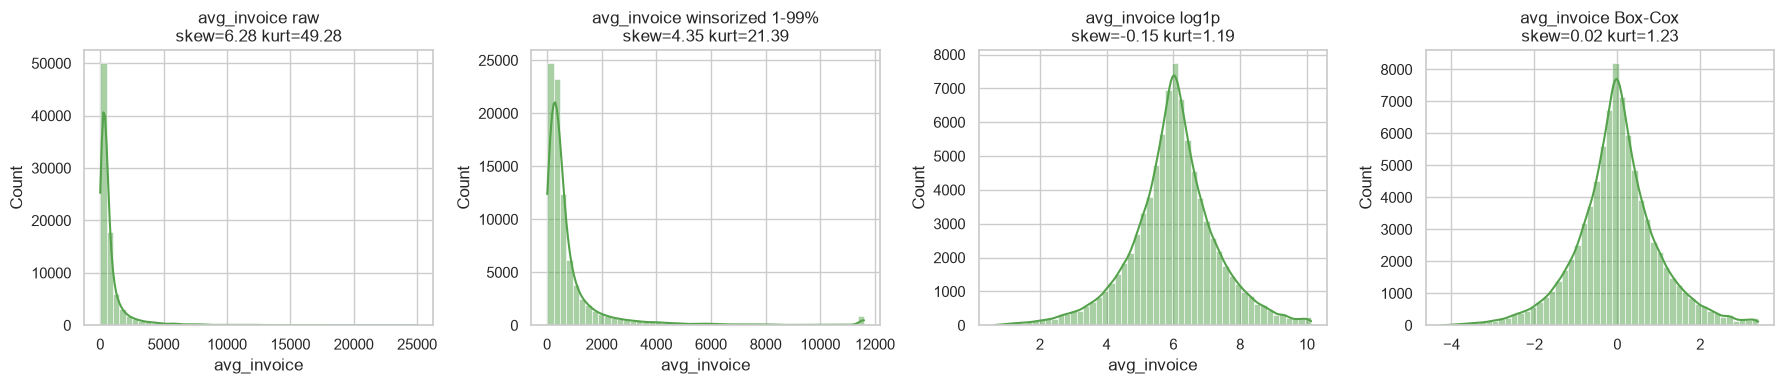

In [10]:
rows = []
for c in ['invoice_count','total_billed','avg_invoice','days_since_last']:
    x = bil[[c]].dropna()
    versions = {'raw': x[c].values,
                'minmax': MinMaxScaler().fit_transform(x)[:,0],
                'zscore': StandardScaler().fit_transform(x)[:,0],
                'log1p': np.log1p(x[c].values),
                'sqrt': np.sqrt(x[c].values),
                'boxcox': PowerTransformer('box-cox').fit_transform(x)[:,0] if (x[c]>0).all() else np.full(len(x), np.nan),
                'yeo-johnson': PowerTransformer('yeo-johnson').fit_transform(x)[:,0]}
    for n, v in versions.items():
        rows.append((c, n, round(stats.skew(v),3), round(stats.kurtosis(v),3)))
tr = pd.DataFrame(rows, columns=['column','transform','skew','ex_kurt'])
print('SKEW after each transform'); display(tr.pivot(index='column', columns='transform', values='skew'))
print('KURTOSIS after each transform'); display(tr.pivot(index='column', columns='transform', values='ex_kurt'))

fig, ax = plt.subplots(1, 4, figsize=(18, 4)); x = bil.avg_invoice
for a, (t, v) in zip(ax, [('raw', x), ('winsorized 1-99%', x.clip(x.quantile(.01), x.quantile(.99))), ('log1p', np.log1p(x)),
                          ('Box-Cox', pd.Series(PowerTransformer('box-cox').fit_transform(x.to_frame())[:,0]))]):
    sns.histplot(v, bins=50, kde=True, ax=a, color='#54A24B'); a.set_title(f'avg_invoice {t}\nskew={v.skew():.2f} kurt={v.kurt():.2f}')
plt.tight_layout(); plt.show()

**Reading:** for `avg_invoice` Box-Cox / Yeo-Johnson give skew ~0.01-0.02 (best). For the flat columns, log makes skew worse, so only standardize them (Z-score) when a model needs scaled inputs.

## 9. Correlation, heatmap and network
- **Pearson:** linear relationship (sensitive to outliers).
- **Spearman:** rank-based (robust to outliers and curved relationships).

invoice_count vs total_billed: r=-0.0018, p=0.597  (p>0.05 -> no relationship)


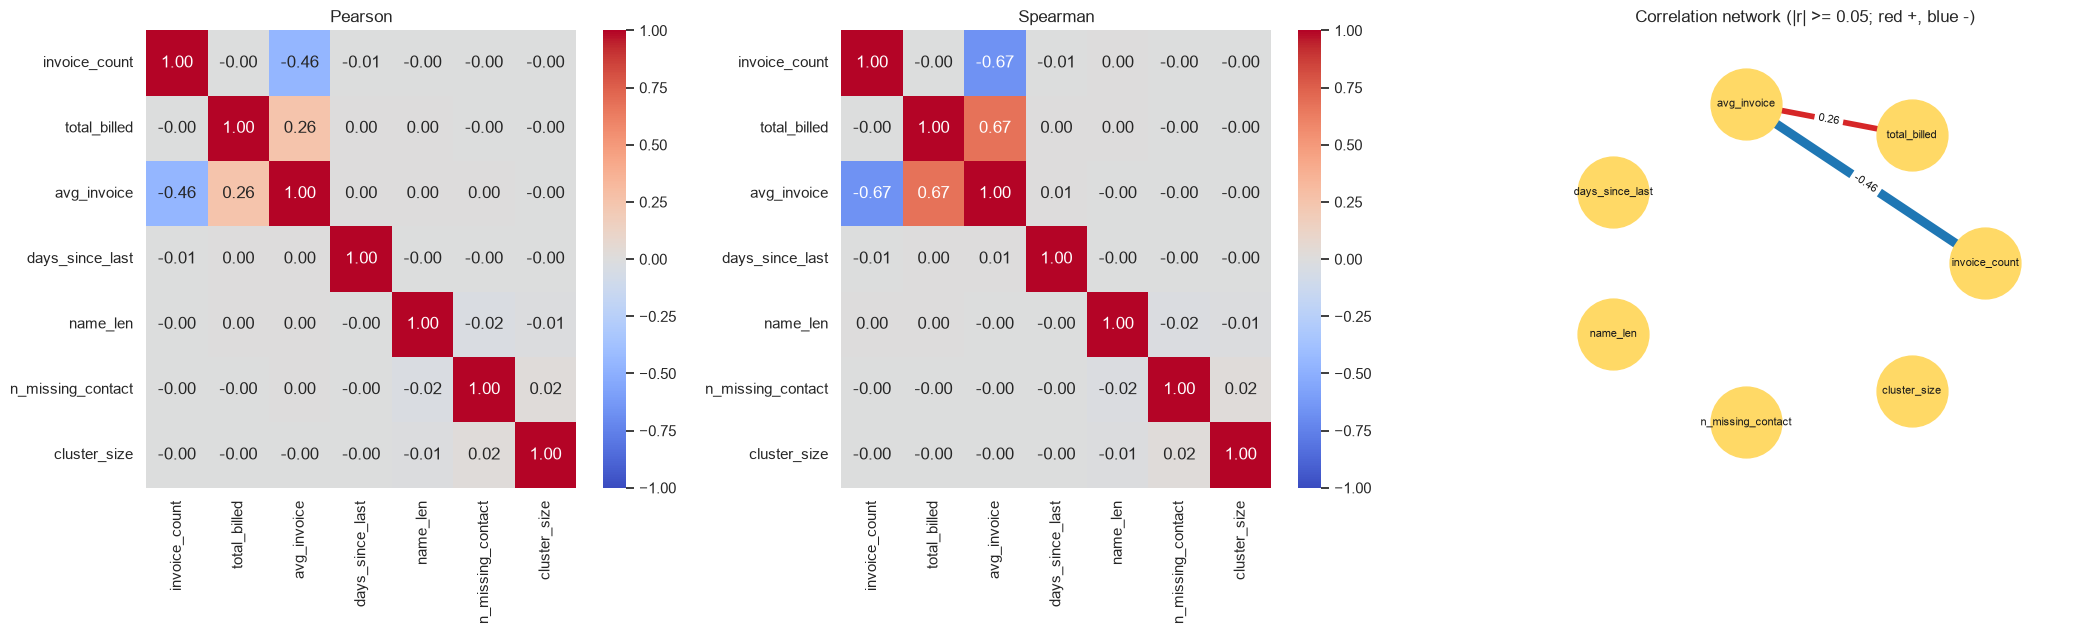

In [11]:
core = ['invoice_count','total_billed','avg_invoice','days_since_last','name_len','n_missing_contact','cluster_size']
Bc = bil[core].dropna()
pe, sp = Bc.corr(), Bc.corr('spearman')
r, p = stats.pearsonr(Bc.invoice_count, Bc.total_billed)
print(f'invoice_count vs total_billed: r={r:.4f}, p={p:.3f}  (p>0.05 -> no relationship)')

fig, ax = plt.subplots(1, 3, figsize=(21, 6.5))
sns.heatmap(pe, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title('Pearson')
sns.heatmap(sp, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title('Spearman')
G = nx.Graph(); G.add_nodes_from(pe.columns)
THRESH = 0.05
for i in pe.columns:
    for k in pe.columns:
        if i < k and abs(pe.loc[i,k]) >= THRESH: G.add_edge(i, k, w=pe.loc[i,k])
pos = nx.circular_layout(G)
nx.draw_networkx(G, pos, ax=ax[2], node_color='#ffd966', node_size=2600, font_size=8,
                 width=[abs(G[u][v]['w'])*12+1 for u,v in G.edges],
                 edge_color=['#d62728' if G[u][v]['w']>0 else '#1f77b4' for u,v in G.edges])
nx.draw_networkx_edge_labels(G, pos, {(u,v): f"{G[u][v]['w']:.2f}" for u,v in G.edges}, ax=ax[2], font_size=8)
ax[2].set_title(f'Correlation network (|r| >= {THRESH}; red +, blue -)'); ax[2].axis('off'); ax[2].margins(0.2)
plt.tight_layout(); plt.show()

**Reading:** the only links are `avg_invoice` with `invoice_count` and `total_billed`, and that is by construction (avg = total / count). Everything else is ~0.

## 10. Multicollinearity - VIF
VIF tells how well a column is predicted by the other columns. VIF < 5 is fine, > 10 is a problem. Computed from the diagonal of the inverse correlation matrix (no statsmodels needed).

In [12]:
def vif(d):
    inv = np.linalg.inv(np.corrcoef(d.values, rowvar=False))
    return pd.Series(np.diag(inv), index=d.columns, name='VIF').round(2)
print('VIF with avg_invoice:');    display(vif(Bc))
print('VIF without avg_invoice:'); display(vif(Bc.drop(columns=['avg_invoice'])))

VIF with avg_invoice:


invoice_count        1.29
total_billed         1.09
avg_invoice          1.38
days_since_last      1.00
name_len             1.00
n_missing_contact    1.00
cluster_size         1.00
Name: VIF, dtype: float64

VIF without avg_invoice:


invoice_count        1.0
total_billed         1.0
days_since_last      1.0
name_len             1.0
n_missing_contact    1.0
cluster_size         1.0
Name: VIF, dtype: float64

**Reading:** all VIFs are 1.0 to 1.4, so there is no multicollinearity. `avg_invoice` is derived, so avoid using it together with `total_billed` and `invoice_count` in one model.

## 11. Independence
**Variables** - Chi-square test + **Cramer's V** (effect size 0 to 1). Large n makes p tiny even for weak effects, so always read V.
**Rows** - ICC (intraclass correlation) of billing numbers for records of the same customer.

In [13]:
def cramers(a, b):
    ct = pd.crosstab(a, b); c2, p, dof, _ = stats.chi2_contingency(ct)
    return c2, p, dof, np.sqrt(c2 / (ct.values.sum() * (min(ct.shape)-1)))
tests = [('payment_method x city', bil.payment_method, bil.city),
         ('status x city', crm.customer_status, crm.city),
         ('source x phone_missing', df.source_system, df.phone.isna()),
         ('source x address_missing', df.source_system, df.address.isna()),
         ('source x email_missing', df.source_system, df.email.isna()),
         ('payment x n_missing_contact', bil.payment_method, bil.n_missing_contact)]
res = []
for nm, a, b in tests:
    c2, p, dof, v = cramers(a, b)
    res.append((nm, round(c2,1), dof, p, round(v,4), 'independent' if p>.05 else 'dependent'))
display(pd.DataFrame(res, columns=['pair','chi2','dof','p_value','CramersV','verdict']))
print('zip -> city: cities per zip =', df.groupby('zip_code').city.nunique().value_counts().to_dict(), '(zip determines city)')

# row independence: records of the same customer
multi = bil.groupby('true_customer_id').filter(lambda x: len(x) > 1)
def icc(d, c):
    k = d.groupby('true_customer_id')[c]; n, m, grand = k.size(), k.mean(), d[c].mean()
    msb = (n*(m-grand)**2).sum()/(len(n)-1)
    msw = ((d[c]-d.true_customer_id.map(m))**2).sum()/(len(d)-len(n))
    n0 = (len(d)-(n**2).sum()/len(d))/(len(n)-1)
    return (msb-msw)/(msb+(n0-1)*msw)
print('\nICC total_billed  :', round(icc(multi,'total_billed'),4))
print('ICC invoice_count :', round(icc(multi,'invoice_count'),4), ' (~0 -> billing numbers independent between duplicates)')
print('But rows ARE dependent in name/email/phone/address (same customer). Use GroupKFold by true_customer_id when splitting train/test.')

,pair,chi2,dof,p_value,CramersV,verdict
0,payment_method x city,26.3,36,8.821174e-01,0.0102,independent
1,status x city,214.3,12,3.666718e-39,0.0463,dependent
2,source x phone_missing,414.3,1,4.251635e-92,0.0473,dependent
3,source x address_missing,3613.8,1,0.000000e+00,0.1398,dependent
4,source x email_missing,1752.4,1,0.000000e+00,0.0973,dependent
5,payment x n_missing_contact,7.6,9,5.753239e-01,0.0055,independent


zip -> city: cities per zip = {1: 12, 2: 1} (zip determines city)

ICC total_billed  : 0.0061
ICC invoice_count : -0.0168  (~0 -> billing numbers independent between duplicates)
But rows ARE dependent in name/email/phone/address (same customer). Use GroupKFold by true_customer_id when splitting train/test.


## 12. Comparison of means and variances
Order: first check equal variances (**Levene**, robust to non-normality; **Bartlett** only for normal data), then compare means (**ANOVA / Welch t**), and also the non-parametric versions (**Kruskal-Wallis / Mann-Whitney**). **Cohen's d** gives effect size (0.2 small, 0.5 medium, 0.8 large).

--- total_billed etc. by payment_method (4 groups) ---


,column,Levene_p,Bartlett_p,ANOVA_p,Kruskal_p
0,total_billed,0.3202,0.6899,0.2216,0.2222
1,invoice_count,0.1345,0.5950,0.4172,0.4164
2,avg_invoice,0.3514,0.0000,0.2560,0.0360
3,days_since_last,0.1886,0.6964,0.5362,0.5358


--- by top-5 cities ---


,column,Levene_p,ANOVA_p,Kruskal_p
0,total_billed,0.1576,0.3479,0.3474
1,invoice_count,0.6854,0.1883,0.1877


--- two-group comparisons ---


,comparison,mean_A,mean_B,Levene_p,Welch_t_p,MannWhitney_p,Cohen_d
0,CRM tenure: Active vs Inactive,14.61,10.04,0.000000e+00,0.000000,8.724204e-17,0.374
1,name_len: Billing vs CRM,13.05,14.51,3.737093e-26,0.000000,0.000000e+00,-0.473
2,total_billed: email present vs missing,12593.05,12306.29,4.304608e-02,0.025537,2.763441e-02,0.040
3,total_billed: cluster>2 vs <=2,12588.13,12579.65,5.652833e-01,0.870979,8.710786e-01,0.001


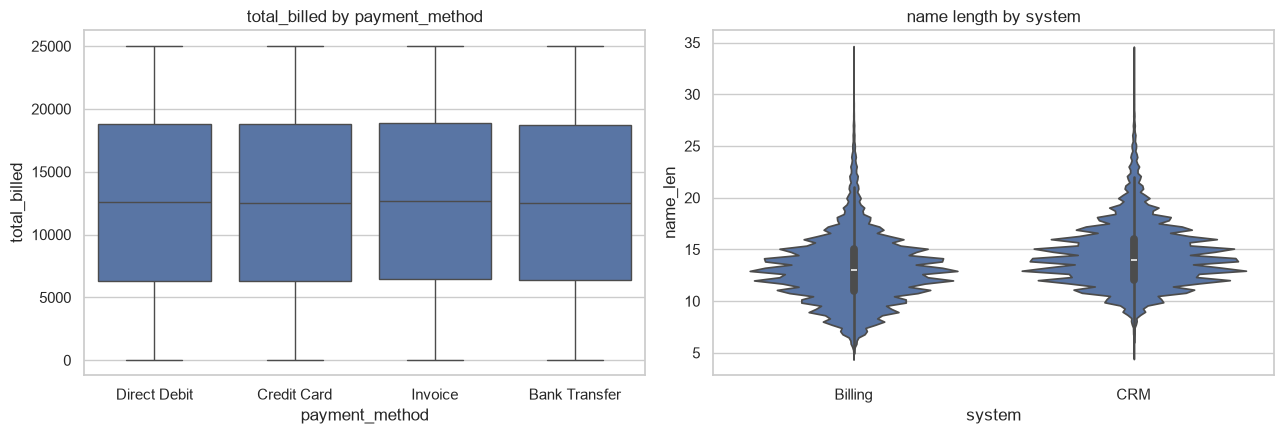

In [14]:
def cohen_d(a, b): return (a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2)

print('--- total_billed etc. by payment_method (4 groups) ---')
rows = []
for c in ['total_billed','invoice_count','avg_invoice','days_since_last']:
    gs = [g[c].dropna().values.astype(float) for _, g in bil.groupby('payment_method')]
    rows.append((c, stats.levene(*gs).pvalue, stats.bartlett(*gs).pvalue, stats.f_oneway(*gs).pvalue, stats.kruskal(*gs).pvalue))
display(pd.DataFrame(rows, columns=['column','Levene_p','Bartlett_p','ANOVA_p','Kruskal_p']).round(4))

print('--- by top-5 cities ---')
top5 = bil[bil.city.isin(bil.city.value_counts().index[:5])]
rows = []
for c in ['total_billed','invoice_count']:
    gs = [g[c].dropna().values.astype(float) for _, g in top5.groupby('city')]
    rows.append((c, stats.levene(*gs).pvalue, stats.f_oneway(*gs).pvalue, stats.kruskal(*gs).pvalue))
display(pd.DataFrame(rows, columns=['column','Levene_p','ANOVA_p','Kruskal_p']).round(4))

print('--- two-group comparisons ---')
def two(nm, a, b):
    return (nm, round(a.mean(),2), round(b.mean(),2), stats.levene(a,b).pvalue,
            stats.ttest_ind(a,b,equal_var=False).pvalue, stats.mannwhitneyu(a,b).pvalue, round(cohen_d(a,b),3))
rows = [two('CRM tenure: Active vs Inactive', crm[crm.customer_status=='Active'].tenure_years.dropna(), crm[crm.customer_status=='Inactive'].tenure_years.dropna()),
        two('name_len: Billing vs CRM', bil.name_len, crm.name_len),
        two('total_billed: email present vs missing', bil[bil.email.notna()].total_billed, bil[bil.email.isna()].total_billed),
        two('total_billed: cluster>2 vs <=2', bil[bil.cluster_size>2].total_billed, bil[bil.cluster_size<=2].total_billed)]
display(pd.DataFrame(rows, columns=['comparison','mean_A','mean_B','Levene_p','Welch_t_p','MannWhitney_p','Cohen_d']))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=bil, x='payment_method', y='total_billed', ax=ax[0]); ax[0].set_title('total_billed by payment_method')
sns.violinplot(data=pd.concat([bil.assign(system='Billing')[['name_len','system']], crm.assign(system='CRM')[['name_len','system']]]),
               x='system', y='name_len', ax=ax[1]); ax[1].set_title('name length by system')
plt.tight_layout(); plt.show()

**Reading:** payment method / city do not change billing numbers (p > 0.05). Real differences: CRM tenure (Active older), and name length (Billing names are shorter because of initials, Cohen's d about -0.47). With a very small p (shown as 0) the value is below floating-point precision.

## 13. Which fields help find duplicates?
For every true duplicate pair (sample), how often do the two records agree on a field? This guides the **blocking** and **similarity** design.

Phone formats:


phone
(xxx) xxx-xxxx     97371
missing            46295
other              13973
+1 xxx xxx xxxx    13711
xxx-xxx-xxxx       13650
Name: count, dtype: int64

Placeholder phones (shared by many people):


phone_n
3360000000    548
9999999999    119
0000000000     58
Name: count, dtype: int64

Most repeated addresses:


address
700 E Haggard Ave    193
115 E Haggard Ave     57
103 E Haggard Ave     48
Name: count, dtype: int64

Names that start with an initial:  {'BILLING': 0.184, 'CRM': 0.0}
32,061 true duplicate pairs sampled


,% pairs agreeing
name_exact,20.9
address_exact,54.1
email_exact,57.0
phone_normalised,70.8
email_local_part,74.8
email_OR_phone,91.9
zip,100.0


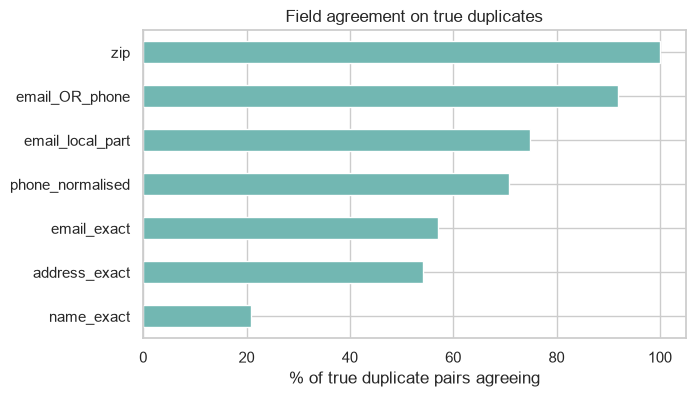

Blocking candidates (pairs to compare):


,key,blocks,candidate_pairs,largest_block
0,zip_code,13,2981816324,46971
1,city,13,4533208528,81415
2,em_local,106051,88414,4
3,phone_n,65687,261510,548


In [15]:
def normp(p):
    if pd.isna(p): return np.nan
    d = re.sub(r'\D', '', p); return d[1:] if len(d)==11 and d[0]=='1' else d
df['phone_n']   = df.phone.map(normp)
df['em_local']  = df.email.str.split('@').str[0].str.lower()

print('Phone formats:'); 
def fmt(p):
    if pd.isna(p): return 'missing'
    if re.fullmatch(r'\(\d{3}\) \d{3}-\d{4}', p): return '(xxx) xxx-xxxx'
    if re.fullmatch(r'\+1 \d{3} \d{3} \d{4}', p): return '+1 xxx xxx xxxx'
    if re.fullmatch(r'\d{3}-\d{3}-\d{4}', p): return 'xxx-xxx-xxxx'
    return 'other'
display(df.phone.map(fmt).value_counts())
print('Placeholder phones (shared by many people):'); display(df.phone_n.value_counts().head(3))
print('Most repeated addresses:'); display(df.address.value_counts().head(3))
print('Names that start with an initial: ', df.groupby('source_system').full_name.apply(lambda s: s.str.match(r'^[A-Z]\.\s').mean()).round(3).to_dict())

szs = df.groupby('true_customer_id').size()
samp = df[df.true_customer_id.isin(szs[szs>1].sample(20000, random_state=1).index)]
agree, tot = {}, 0
for _, grp in samp.groupby('true_customer_id'):
    for a, b in combinations(grp.to_dict('records'), 2):
        tot += 1
        chk = {'email_exact': pd.notna(a['email']) and a['email']==b['email'],
               'email_local_part': pd.notna(a['em_local']) and a['em_local']==b['em_local'],
               'phone_normalised': pd.notna(a['phone_n']) and a['phone_n']==b['phone_n'],
               'address_exact': pd.notna(a['address']) and a['address']==b['address'],
               'name_exact': a['full_name']==b['full_name'],
               'zip': a['zip_code']==b['zip_code']}
        chk['email_OR_phone'] = chk['email_local_part'] or chk['phone_normalised']
        for k, v in chk.items(): agree[k] = agree.get(k, 0) + bool(v)
ag = (pd.Series(agree)/tot*100).round(1).sort_values()
print(f'{tot:,} true duplicate pairs sampled'); display(ag.to_frame('% pairs agreeing'))
ag.plot.barh(figsize=(7,4), color='#72B7B2'); plt.xlabel('% of true duplicate pairs agreeing'); plt.title('Field agreement on true duplicates'); plt.show()

print('Blocking candidates (pairs to compare):')
rows = []
for col in ['zip_code','city','em_local','phone_n']:
    vc = df[col].value_counts(); rows.append((col, len(vc), int((vc*(vc-1)//2).sum()), vc.max()))
display(pd.DataFrame(rows, columns=['key','blocks','candidate_pairs','largest_block']))

## 14. Conclusions
| Topic | Finding | Action |
|---|---|---|
| Duplicates | 314 exact; 95,000 rows share a customer with another row | drop exact, fuzzy-match the rest |
| Missing | phone 25%, address 4.3%, email 2.2%; depends on source | keep nulls + has_x flags; fill from cluster after matching |
| Outliers | only `avg_invoice` (11%) | log / Box-Cox, do not delete |
| Skew / kurtosis | `avg_invoice` skew 6.3, kurt 49; others flat | transform only `avg_invoice` |
| Normality | nothing is normal | non-parametric tests or CLT |
| Correlation / VIF | no real correlation, VIF 1.0 to 1.4 | no multicollinearity (avoid avg_invoice with its parents) |
| Independence | variables independent; rows dependent | GroupKFold by `true_customer_id` |
| Means / variances | payment and city do not matter; name length differs by system (d about -0.47) | standardize names before similarity |
| Matching signals | email local part and phone strongest; name exact only about 21% | block on email local part, cleaned phone, zip + name code; fuzzy name score |